**Instructor:** Dr. Sabyasachi Mukhopadhyay, Outreach Teaching Fellow, Department of Computer Science and Engineering, IIT Kharagpur

**Contact:** sabyasachim@ieee.org

# LoRA & QLoRA: Cost-Efficient Parameter-Efficient Fine-Tuning
## Adapters, Prefix Tuning, and Prompt Tuning — A 3-Hour Hands-On Workshop

**Format:** theory + live, runnable code, entirely on free Google Colab (CPU works throughout; a T4 GPU speeds up Modules 3 & 5 and is required for the QLoRA 4-bit demo).

**No API keys, tokens, or logins are required anywhere in this notebook.** Every model and dataset used is public and open-access on the Hugging Face Hub, and no cell calls `huggingface_hub.login()`, uses an OpenAI/Anthropic key, or logs to a paid experiment tracker.

---

### Learning objectives
By the end of this workshop you will be able to:
1. Explain **why** full fine-tuning of large language models is expensive, and how Parameter-Efficient Fine-Tuning (PEFT) fixes this.
2. Explain the **math and intuition** behind LoRA (low-rank adaptation) and implement it with Hugging Face `peft`.
3. Explain how **QLoRA** combines 4-bit quantization with LoRA, and implement it end-to-end.
4. Explain and implement **Prefix Tuning** and **Prompt Tuning** (soft-prompt methods), and know when they beat/lose to LoRA.
5. **Quantitatively compare** all four methods on trainable-parameter count, memory footprint, training time, and output quality.
6. Save, reload, and **merge** adapters for deployment.

### Agenda

Block | Content |
|---|---|
| Setup | Install libraries, GPU check, load shared model & dataset |
 | Module 1 | **Theory:** Why PEFT? Cost of full fine-tuning, PEFT taxonomy |
 | Module 2 | **LoRA** — theory + hands-on fine-tuning |
 | Module 3 | **QLoRA** — quantization theory + hands-on 4-bit fine-tuning |
 | Break | — |
| Module 4 | **Prefix Tuning & Prompt Tuning** — theory + hands-on |
 | Module 5 | Head-to-head comparison: params, memory, time, quality |
| Wrap-up | Best-practice checklist, exercises, further reading |

### Prerequisites
- Comfortable reading Python and basic PyTorch/Transformers code.
- No prior PEFT experience required — every method is explained from first principles before we code it.

### How to run this notebook
`Runtime → Change runtime type → T4 GPU` (recommended). Then `Runtime → Run all`, or step through cell-by-cell as the workshop proceeds — that is the intended pace.


## 0. Environment Setup  

We install four libraries from the Hugging Face ecosystem:

- **`transformers`** — model/tokenizer loading, training loop (`Trainer`).
- **`peft`** — LoRA / QLoRA / Prefix Tuning / Prompt Tuning implementations.
- **`accelerate`** — hardware-agnostic training backend used internally by `Trainer`.
- **`bitsandbytes`** — 4-bit / 8-bit quantization kernels, needed only for QLoRA (Module 3).
- **`datasets`** — one line to stream a public dataset from the Hub.

All of these are free, open-source pip packages. Nothing here needs an account, a key, or a login.


In [31]:
# Install the libraries this workshop needs.
# -q          : quiet install (less console spam)
# -U          : upgrade to latest compatible version, so the APIs we use below are current
!pip install -q -U transformers peft accelerate bitsandbytes datasets evaluate torchao
# torch is already preinstalled on Colab, so we do not reinstall it here.



**Output Explanation**

| Segment | Meaning |
|---|---|
| `━━━━━...` | A fully filled bar = this file's download is complete. |
| `43.1/43.1 MB` | Bytes downloaded so far / total file size — matching numbers mean it's finished. |
| `17.9 MB/s` | Instantaneous download speed at that moment; varies line to line with network conditions, not a sign of a problem. |
| `eta 0:00:00` | Estimated time remaining — zero means done. |

A rough size sanity-check: `bitsandbytes` ships prebuilt CUDA kernels and is usually the largest single wheel in this install; the smaller hundreds-of-KB downloads are typically lighter dependencies like `tokenizers`, `huggingface-hub`, or `safetensors`, not the top-level libraries themselves (`peft`, `datasets`, `evaluate`, `accelerate` are all fairly small pure-Python packages).

**Nothing here needs any action** — no errors, no prompts, no partial bars stuck mid-way. Occasionally Colab may print *"You must restart the runtime to use newly installed versions"* if an already-imported package got upgraded; if you see it, use `Runtime → Restart runtime` and re-run from the top — a one-time Colab quirk, not a failure. If the cell finishes and the next cell (the GPU check) runs without an `ImportError`, the install succeeded.

### Why torch isn't in this list

Colab images come with a CUDA-matched build of PyTorch preinstalled. Adding `torch` to this `pip install` line risks pip pulling a CPU-only or version-mismatched build that breaks GPU support, so we deliberately leave it alone and rely on Colab's existing installation (checked in the very next cell via `torch.cuda.is_available()`).

In [32]:
# ---- Core imports used throughout the whole notebook ----

import time                       # to time how long each training run takes
import torch                      # PyTorch: tensors, GPU management
import numpy as np                # small numeric helpers (e.g. averaging losses)
import pandas as pd               # to build the comparison table in Module 5
import matplotlib.pyplot as plt   # to plot the comparison chart in Module 5

from datasets import load_dataset                     # one-line public dataset loader (no auth needed)
from transformers import (
    AutoTokenizer,                 # loads the tokenizer that matches our base model
    AutoModelForCausalLM,          # loads a "next-token-prediction" (causal LM) model
    BitsAndBytesConfig,            # describes *how* to quantize a model to 4-bit (used in Module 3)
    TrainingArguments,              # hyperparameters for the training loop
    Trainer,                        # the actual training loop implementation
    DataCollatorForLanguageModeling,  # batches + pads tokenized examples for causal-LM training
    set_seed,                       # fixes all random seeds for reproducibility
)
from peft import (
    LoraConfig,                    # config class for LoRA / QLoRA adapters
    PrefixTuningConfig,             # config class for Prefix Tuning
    PromptTuningConfig,              # config class for Prompt Tuning
    PromptTuningInit,                 # enum: how to initialize the soft prompt (RANDOM vs TEXT)
    TaskType,                          # tells peft what kind of head/task we are adapting (causal LM here)
    get_peft_model,                     # wraps a base model with a PEFT config -> trainable adapter model
    prepare_model_for_kbit_training,     # patches a quantized model so gradients flow correctly (QLoRA)
    PeftModel,                             # class used to reload a saved adapter onto a base model
)

set_seed(42)  # fix seeds (Python, NumPy, PyTorch, CUDA) so results are reproducible across runs

# Detect whether a GPU is available. QLoRA's 4-bit kernels REQUIRE a CUDA GPU;
# LoRA / Prefix / Prompt tuning will happily run on CPU too, just more slowly.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
if DEVICE == "cpu":
    print("No GPU detected. Modules 1, 2 and 4 will still run (slowly). "
          "Module 3 (QLoRA) needs a GPU: go to Runtime > Change runtime type > T4 GPU, then re-run this cell.")
else:
    print(f"GPU detected: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU detected: Tesla T4


**Output Explanation**

This is the printout from the GPU-detection cell (`DEVICE = "cuda" if torch.cuda.is_available() else "cpu"`), and it's the "green light" signal for the whole workshop:

| Line | Meaning |
|---|---|
| `Using device: cuda` | `torch.cuda.is_available()` returned `True`, so `DEVICE` was set to `"cuda"`. Every model and tensor built later in the notebook (`.to(DEVICE)`) will be placed on the GPU instead of the CPU. |
| `GPU detected: Tesla T4` | `torch.cuda.get_device_name(0)` — the actual GPU model Colab assigned this session. The **T4** is NVIDIA's most common free-tier Colab GPU: 16 GB of VRAM, and — importantly for this workshop — it supports the Turing-generation tensor cores that `bitsandbytes`' 4-bit kernels rely on. |

### Why this matters for the rest of the notebook

- **Modules 1, 2, and 4** (theory, LoRA, Prefix/Prompt Tuning) would still run on a CPU, just much more slowly — seeing `cuda` here means they'll instead run in seconds rather than minutes.
- **Module 3 (QLoRA) needs this line to say `cuda`.** The `QLORA_AVAILABLE = torch.cuda.is_available()` guard cell later in the notebook checks exactly this, and 4-bit quantization simply cannot run on CPU — if this cell had printed `Using device: cpu`, Module 3 would print a warning and skip itself instead of erroring out.
- The `fp16=torch.cuda.is_available()` / `bf16=True` settings used in every `TrainingArguments` block later assume a GPU is present — seeing `Tesla T4` here confirms those mixed-precision settings will actually take effect rather than being silently ignored on CPU.

### If you see `Using device: cpu` instead

That means no GPU is attached to this runtime. Go to `Runtime → Change runtime type → Hardware accelerator → GPU (T4)`, save, and re-run the notebook from the top — Colab's free T4 allocation is what this whole workshop (especially Module 3) is designed around. It's not guaranteed on every session (Colab allocates GPUs based on availability and usage quotas), so if none is offered immediately, waiting a few minutes and retrying usually works.

In [33]:
# ---- Shared configuration used by every module below ----
# Using the SAME base model and SAME dataset for every PEFT method lets us make a fair,
# apples-to-apples comparison in Module 5 (same starting point, same task).

BASE_MODEL_NAME = "gpt2"                 # 124M-parameter public model, no license gate, downloads in seconds
DATASET_NAME = "Abirate/english_quotes"  # ~2,500 public-domain-style quotes, no auth needed
MAX_SEQ_LEN = 64                          # short sequences keep every demo fast on CPU or a free-tier GPU
N_TRAIN_EXAMPLES = 400                     # small training subset -> each run finishes in ~1-2 minutes
N_EVAL_EXAMPLES = 50                        # small held-out slice for quick qualitative checks

print(f"Base model : {BASE_MODEL_NAME}")
print(f"Dataset    : {DATASET_NAME}")


Base model : gpt2
Dataset    : Abirate/english_quotes


**Output Explanation**

**`gpt2`** is the 124M-parameter causal language model every module (LoRA, QLoRA, Prefix Tuning, Prompt Tuning) will adapt, chosen because it's small, public, and needs no login. **`Abirate/english_quotes`** is the ~2,500-row public dataset of quotes used to fine-tune it, also public and login-free. Seeing both names printed here is just a sanity check that these shared variables are set before the tokenizer, model, and dataset loading cells below consume them.

### Load the shared tokenizer and dataset

We tokenize once and reuse the tokenized dataset for every PEFT method below, so training time differences
in Module 5 reflect the *method*, not different data pipelines.


In [34]:
# Load the tokenizer that matches gpt2's vocabulary and byte-pair-encoding rules.
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# GPT-2's tokenizer has no padding token by default (it was trained without one).
# We reuse the end-of-sequence token as the padding token so batching/padding works.
tokenizer.pad_token = tokenizer.eos_token

# Load the quotes dataset. It has a single "train" split with a "quote" text field
# (plus "author" and "tags", which we don't need for this language-modeling demo).
raw_dataset = load_dataset(DATASET_NAME)
print(raw_dataset)
print("\nExample raw record:")
print(raw_dataset["train"][0])


DatasetDict({
    train: Dataset({
        features: ['quote', 'author', 'tags'],
        num_rows: 2508
    })
})

Example raw record:
{'quote': '“Be yourself; everyone else is already taken.”', 'author': 'Oscar Wilde', 'tags': ['be-yourself', 'gilbert-perreira', 'honesty', 'inspirational', 'misattributed-oscar-wilde', 'quote-investigator']}


**Output Explanation:**

The **`HF_TOKEN` warning** is expected and harmless — it just means we're downloading from the Hugging Face Hub anonymously (no login), which is exactly this workshop's "no API keys" design; it only affects rate limits/speed, not whether the download succeeds, and it's safe to ignore. It's printed twice because both the underlying library (`huggingface_hub`) and its logger emit it separately.

The lines below that (`config.json`, `tokenizer_config.json`, `vocab.json`, `merges.txt`, `tokenizer.json`, `README.md`) are the small files that make up the **`gpt2` tokenizer and model config**, each downloading to completion in well under a second — this is `AutoTokenizer.from_pretrained("gpt2")` fetching its needed files from the Hub and caching them locally.

The `quotes.jsonl` lines are `load_dataset("Abirate/english_quotes")` fetching the dataset's single data file (~647 kB), followed by `Generating train split` — the `datasets` library parsing all 2,508 rows into an Arrow-backed table.

The final `DatasetDict`/example printout is just our own `print(raw_dataset)` and `print(raw_dataset["train"][0])` calls confirming the load worked: one `train` split, 2,508 rows, three columns (`quote`, `author`, `tags`), and a first example (an Oscar Wilde quote) showing the raw, untokenized text we'll feed to the tokenizer next.

In [35]:
def tokenize_function(examples):
    '''Turn a batch of raw quote strings into fixed-length token-id sequences.'''
    # truncation=True         : cut anything longer than MAX_SEQ_LEN
    # padding="max_length"    : pad everything shorter than MAX_SEQ_LEN with <pad> tokens
    # max_length=MAX_SEQ_LEN  : the fixed sequence length we chose above
    return tokenizer(
        examples["quote"],
        truncation=True,
        padding="max_length",
        max_length=MAX_SEQ_LEN,
    )

# .map() applies tokenize_function to every row of the dataset in batches (fast).
# remove_columns drops the original text columns, since the model only needs token ids from here on.
tokenized_dataset = raw_dataset["train"].map(
    tokenize_function,
    batched=True,
    remove_columns=raw_dataset["train"].column_names,
)

# Shuffle once (seeded) so our small train/eval slices aren't biased by dataset order,
# then take a small slice for training and a separate small slice for qualitative eval.
tokenized_dataset = tokenized_dataset.shuffle(seed=42)
train_dataset = tokenized_dataset.select(range(N_TRAIN_EXAMPLES))
eval_dataset = tokenized_dataset.select(range(N_TRAIN_EXAMPLES, N_TRAIN_EXAMPLES + N_EVAL_EXAMPLES))

print(f"Train examples: {len(train_dataset)}  |  Eval examples: {len(eval_dataset)}")


Train examples: 400  |  Eval examples: 50


**Output Explanation:**

The **`Map: 100%` bar** is `datasets`' progress indicator for `tokenized_dataset = raw_dataset["train"].map(tokenize_function, batched=True, ...)` — it's tokenizing (and truncating/padding to `MAX_SEQ_LEN`) all 2,508 quotes, processing them at ~5,600 examples/second since batching makes this very fast even on CPU.

**`Train examples: 400 | Eval examples: 50`** confirms the two small slices we carved out of that tokenized dataset: `train_dataset` (400 examples, via `.select(range(N_TRAIN_EXAMPLES))`) used to actually fine-tune each PEFT method, and `eval_dataset` (the next 50 examples) held out for qualitative checks. Both are deliberately tiny subsets of the full 2,508 rows so every training run in the workshop finishes in about a minute rather than tokenizing/training on the whole dataset.

In [36]:
# A data collator batches individual tokenized examples into training-ready tensors.
# mlm=False -> causal (next-token) language modeling, NOT masked language modeling (that's BERT-style).
# This collator also builds the "labels" tensor for us (a shifted copy of input_ids).
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)


def count_parameters(model):
    '''Return (trainable_params, total_params) for any PyTorch model.'''
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)  # only params that get gradients
    total = sum(p.numel() for p in model.parameters())                        # every parameter, frozen or not
    return trainable, total


def generate_sample(model, prompt="The secret to a good life is", max_new_tokens=30):
    '''Greedy-ish generation helper so we can eyeball output quality after each method.'''
    model.eval()  # disable dropout etc. for generation
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)  # tokenize the prompt onto the model's device
    with torch.no_grad():  # no need to track gradients just to generate text
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,   # how many new tokens to generate after the prompt
            do_sample=True,                   # sample instead of pure greedy decoding, for more natural text
            top_p=0.9,                          # nucleus sampling: only sample from the top 90% probability mass
            temperature=0.8,                      # slightly sharpen the distribution vs. fully random sampling
            pad_token_id=tokenizer.eos_token_id,     # tell generate() what padding id to use if needed
        )
    model.train()  # switch back to train mode (matters for dropout/quantization layers)
    return tokenizer.decode(output_ids[0], skip_special_tokens=True)


def gpu_mem_mb():
    '''Current GPU memory allocated by this process, in megabytes (0 if no GPU).'''
    if torch.cuda.is_available():
        return torch.cuda.memory_allocated() / (1024 ** 2)
    return 0.0


# This dictionary will collect one row of stats per PEFT method for the Module 5 comparison.
results = {}


In [37]:
# ---- Baseline: what does the UN-fine-tuned model produce? ----
# We load a plain copy of gpt2 purely to show a "before" sample; every module below
# will load its OWN fresh copy of gpt2 so the four methods never share (or corrupt) weights.

baseline_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_NAME).to(DEVICE)
trainable, total = count_parameters(baseline_model)
print(f"Base gpt2 -> trainable: {trainable:,} | total: {total:,} (100% trainable, since nothing is frozen)")

print("\nBaseline generation (before any fine-tuning):")
print(generate_sample(baseline_model))

# Free this copy's memory now; we only needed it for the "before" sample.
del baseline_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Base gpt2 -> trainable: 124,439,808 | total: 124,439,808 (100% trainable, since nothing is frozen)

Baseline generation (before any fine-tuning):
The secret to a good life is to have good ideas," said the author. "It is hard to get good ideas if you don't have a good plan."

The study


**Output Explanation**


**`model.safetensors`** is `gpt2`'s actual weight file downloading (in the safe, non-pickle `.safetensors` format) — the split "reconstructing file: 548MB" vs. "downloading bytes: 474MB" reflects the Hub's newer chunk-deduplication transfer method, landing at gpt2's expected full-precision size (~548MB for 124M fp32 parameters). **`Loading weights: 148/148`** is `transformers` loading each of gpt2's 148 individual weight tensors (embeddings, 12 transformer blocks' worth of attention/MLP weights, etc.) into memory. **`generation_config.json`** is a small file of default text-generation hyperparameters (e.g. `pad_token_id`) shipped alongside the model.

**`trainable: 124,439,808 | total: 124,439,808 (100%)`** confirms this is the *plain, un-adapted* baseline model — every one of its 124M parameters is still trainable because no LoRA/prefix/prompt config has been applied yet (that changes starting in Module 2).

The **baseline generation** is what plain `gpt2` produces on the prompt *"The secret to a good life is..."* with no fine-tuning at all — grammatically fluent but generic, news-article-like continuation rather than the punchy, quote-style completion we'll compare it against once each PEFT method has fine-tuned it on the `english_quotes` dataset.

## Module 1 — Why Parameter-Efficient Fine-Tuning?  

### 1.1 The cost of full fine-tuning

Full fine-tuning updates **every** weight in the model. For each trainable parameter, Adam-family optimizers
(the default for LLMs) need to store, in addition to the parameter itself:

| Quantity | Bytes / parameter (fp16 weights + fp32 Adam states) |
|---|---|
| Model weight | 2 bytes (fp16) |
| Gradient | 2 bytes (fp16) |
| Adam first moment (m) | 4 bytes (fp32) |
| Adam second moment (v) | 4 bytes (fp32) |
| **Total** | **≈ 12 bytes / parameter** |

So fine-tuning a 7-billion-parameter model needs roughly **7B × 12 bytes ≈ 84 GB** of accelerator memory just for
weights + gradients + optimizer state — before you even add activations. That is more memory than a single
consumer GPU (and most single data-center GPUs) provide.

There is a second, quieter cost: **storage and deployment**. If you fine-tune a 7B model for 20 different
customers/tasks, full fine-tuning gives you 20 full copies of a 14 GB (fp16) checkpoint — **280 GB** to store
and to load/swap in production.

There is a third cost: **catastrophic forgetting**. Updating every weight can overwrite general-purpose
knowledge the model learned during pretraining, especially with small fine-tuning datasets like the one we use
today.

### 1.2 The PEFT idea

Parameter-Efficient Fine-Tuning methods freeze almost all of the pretrained weights and train only a small
number of **new or selected** parameters (often < 1% of the total). This attacks all three costs at once:

- **Memory:** gradients & optimizer states are only needed for the tiny trainable slice.
- **Storage:** you only save the small adapter (often a few MB), not a full model copy per task.
- **Forgetting:** the frozen backbone keeps its pretrained knowledge intact.

### 1.3 A quick taxonomy

| Family | Idea | Examples |
|---|---|---|
| **Additive** | Insert new trainable modules/parameters; keep everything else frozen | Adapters, **Prefix Tuning**, **Prompt Tuning** |
| **Reparameterization** | Represent the weight *update* with a low-rank (small) set of parameters | **LoRA**, QLoRA (LoRA + quantization) |
| **Selective** | Train a small existing subset of the original weights, freeze the rest | BitFit (biases only) |

Today's workshop covers the two most widely used families in practice: **LoRA/QLoRA** (reparameterization) and
**Prefix/Prompt Tuning** (additive, "soft prompt" style).


In [38]:
# A tiny numeric illustration of the memory argument above, using a hypothetical 7B model.

model_params = 7_000_000_000                 # 7 billion parameters, a common "small" open LLM size
bytes_per_param_full_ft = 12                    # weight(fp16) + grad(fp16) + Adam m,v (fp32 each) = 2+2+4+4
bytes_per_param_lora = 12                          # LoRA trains ~0.1-1% of params, but at the SAME 12 bytes/param rate

full_ft_gb = model_params * bytes_per_param_full_ft / (1024 ** 3)   # convert bytes -> gigabytes
lora_fraction = 0.005                                                  # assume LoRA trains 0.5% of all parameters
lora_trainable_params = model_params * lora_fraction
lora_gb = lora_trainable_params * bytes_per_param_lora / (1024 ** 3)

print(f"Full fine-tuning optimizer+grad memory : ~{full_ft_gb:,.1f} GB")
print(f"LoRA (0.5% trainable) optimizer+grad memory : ~{lora_gb:,.2f} GB")
print(f"Reduction: ~{full_ft_gb / lora_gb:,.0f}x smaller")
# Note: this ignores activation memory and the (still large) frozen weights that must be held in memory too -
# QLoRA's contribution (Module 3) is precisely to shrink THAT remaining frozen-weight memory via quantization.


Full fine-tuning optimizer+grad memory : ~78.2 GB
LoRA (0.5% trainable) optimizer+grad memory : ~0.39 GB
Reduction: ~200x smaller


**Output Explanation**

This is the result of the toy memory-math cell illustrating Module 1's cost argument, using a **hypothetical 7-billion-parameter model** (not `gpt2`, which is far smaller) as a stand-in for a realistic modern LLM.

**`Full fine-tuning: ~78.2 GB`** is `7B params × 12 bytes` (2 bytes fp16 weight + 2 bytes fp16 gradient + 4+4 bytes fp32 Adam moments), converted to gigabytes — the optimizer+gradient memory a full fine-tune would need, before even counting activations.

**`LoRA (0.5% trainable): ~0.39 GB`** applies that same 12-bytes-per-parameter cost, but only to the assumed 0.5% of parameters (~35M) that LoRA actually trains — everything else stays frozen and needs no gradient or optimizer state at all.

**`Reduction: ~200x smaller`** is simply `78.2 / 0.39`, making concrete the Module 1 claim that training a small adapter instead of the whole model can shrink optimizer+gradient memory by roughly two orders of magnitude — the core economic argument for PEFT before we even touch code.

## Module 2 — LoRA: Low-Rank Adaptation  

### 2.1 The core idea

LoRA (Hu et al., 2021, *"LoRA: Low-Rank Adaptation of Large Language Models"*) starts from an observation: when
you fine-tune a pretrained weight matrix `W0` (shape `d x k`), the **update** `ΔW` that fine-tuning would have
applied tends to have a low "intrinsic rank" — most of the useful update lives in a small subspace.

So instead of learning a full, dense `ΔW` (which has `d x k` parameters, exactly as many as `W0` itself), LoRA
**factorizes** it into two small matrices:

```
ΔW = B @ A          where  B is (d x r),  A is (r x k),   and r << min(d, k)
```

The forward pass becomes:

```
h = W0 x + ΔW x = W0 x + (alpha / r) * B (A x)
```

- `W0` stays **completely frozen** — it is never touched, so we save its optimizer state entirely.
- Only `A` and `B` are trained. Parameter count: `r*(d+k)` instead of `d*k`. For `r=8` on a `768x768` GPT-2
  attention matrix, that is `8*(768+768) = 12,288` parameters instead of `768*768 = 589,824` — a **~48x** reduction
  for that one matrix.
- `alpha` is a fixed scaling constant; `alpha / r` scales the adapter's contribution so its magnitude stays
  sensible as you change `r`. A common default is `alpha = 2 * r`.
- `A` is initialized with small random values, `B` is initialized to **all zeros** — so at step 0, `ΔW = 0` and
  the adapted model behaves exactly like the frozen base model. Training then gradually "grows" the adapter's
  contribution.

### 2.2 Where do we insert LoRA adapters?

LoRA is normally applied to the linear projections inside self-attention (query/key/value/output projections),
sometimes also to the feed-forward layers. GPT-2's attention block uses one **fused** `Conv1D` layer called
`c_attn` (instead of separate `q_proj`/`k_proj`/`v_proj` like Llama-style models), so for GPT-2 we target
`target_modules=["c_attn"]`.

### 2.3 Key hyperparameters

| Parameter | Meaning | Typical value |
|---|---|---|
| `r` | rank of the low-rank update (bigger = more capacity, more params) | 4–64 |
| `lora_alpha` | scaling factor (effective scale = `alpha / r`) | `2 * r` |
| `lora_dropout` | dropout applied to the adapter path only, for regularization | 0.0–0.1 |
| `target_modules` | which existing layers get an adapter attached | model-architecture-specific |

Let's implement it.


In [39]:
# Load a FRESH copy of the base model dedicated to the LoRA experiment.
# (Every module in this workshop loads its own fresh copy so the four methods never interfere with each other.)
lora_base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_NAME).to(DEVICE)

# Describe the LoRA adapter we want to attach.
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,   # we are adapting a causal (next-token-prediction) language model
    r=8,                             # rank of the low-rank decomposition (see 2.1 above)
    lora_alpha=16,                    # scaling factor; effective scale = lora_alpha / r = 16/8 = 2
    lora_dropout=0.05,                  # small dropout on the adapter path, helps avoid overfitting on 400 examples
    target_modules=["c_attn"],           # GPT-2's fused attention projection layer (see 2.2 above)
    bias="none",                          # do not train any bias terms, only the LoRA A/B matrices
)

# get_peft_model() wraps the frozen base model with trainable LoRA adapters attached at target_modules.
lora_model = get_peft_model(lora_base_model, lora_config)

# print_trainable_parameters() is a peft convenience method that reports exactly what we discussed in Module 1.
lora_model.print_trainable_parameters()


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364


/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2733: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


**Output Explanation**


**`trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364`** is `lora_model.print_trainable_parameters()` confirming LoRA actually attached: only ~295K of gpt2's ~125M parameters are trainable (0.24%) — the rest stay frozen. This matches the math from Module 2's theory: each of GPT-2's 12 `c_attn` layers gets an `A` (8×768) and `B` (2304×8) matrix, i.e. `(8×768 + 2304×8) = 24,576` params/layer × 12 layers = 294,912. (Total params also ticked up slightly from 124,439,808 to 124,734,720 — that's the new LoRA `A`/`B` matrices being added on top of the original weights.)

**The `UserWarning`** is `peft` noticing that GPT-2's `c_attn` is a `Conv1D` layer (weights stored transposed) rather than the more common `nn.Linear`, and automatically flipping its internal `fan_in_fan_out` flag to orient the LoRA matrices correctly for that layout. This is expected specifically for GPT-2-family models, is handled automatically, and needs no action — it's informational, not an error.

In [40]:
# Inspect exactly which sub-modules became trainable, to make the "only a sliver of the model" idea concrete.

# named_parameters() yields (name, tensor) for EVERY parameter in the model, frozen or not;
# keeping only names where requires_grad is True filters this down to just the LoRA A/B matrices.
trainable_module_names = [name for name, p in lora_model.named_parameters() if p.requires_grad]

# Should print 24 here (12 transformer blocks x 2 matrices per block: lora_A + lora_B) - see the
# print_trainable_parameters() output above for the parameter-count version of this same fact.
print(f"Number of trainable tensors: {len(trainable_module_names)}")

# A header line so the printed names below are clearly labeled, not just a bare list.
print("First few trainable tensor names:")

# Only print the first 6 of the 24 names (a representative sample), so the cell's output stays short
# instead of dumping all 24 lora_A/lora_B tensor names.
for name in trainable_module_names[:6]:
    # Leading "  " just indents each name two spaces for readability under the header above.
    print(" ", name)


Number of trainable tensors: 24
First few trainable tensor names:
  base_model.model.transformer.h.0.attn.c_attn.lora_A.default.weight
  base_model.model.transformer.h.0.attn.c_attn.lora_B.default.weight
  base_model.model.transformer.h.1.attn.c_attn.lora_A.default.weight
  base_model.model.transformer.h.1.attn.c_attn.lora_B.default.weight
  base_model.model.transformer.h.2.attn.c_attn.lora_A.default.weight
  base_model.model.transformer.h.2.attn.c_attn.lora_B.default.weight


**Output Explanation**

**`Number of trainable tensors: 24`** — this is `len(trainable_module_names)` from the inspection cell: GPT-2 has 12 transformer blocks, and LoRA added exactly 2 trainable matrices per block (`lora_A` and `lora_B` on `c_attn`), so `12 × 2 = 24` trainable tensors total — everything else in the model (embeddings, layer norms, the original `c_attn` weights, etc.) stays frozen.

**The tensor names** show the naming pattern `peft` uses: `base_model.model.transformer.h.{layer_index}.attn.c_attn.lora_{A|B}.default.weight` — `h.0`, `h.1`, `h.2`, … identify which of the 12 transformer blocks each pair belongs to, `lora_A`/`lora_B` are the two low-rank factors from Module 2's `ΔW = B·A`, and `.default` is the adapter's name (relevant later if you ever attach multiple named adapters to one model). Seeing one `lora_A`/`lora_B` pair per layer, in order, confirms the adapter was attached exactly where `target_modules=["c_attn"]` intended.

In [41]:
# ---- Train the LoRA-adapted model ----

lora_training_args = TrainingArguments(
    output_dir="./lora_checkpoints",     # local scratch directory for logs/checkpoints (not uploaded anywhere)
    per_device_train_batch_size=8,          # small batch size keeps this runnable on CPU or a free-tier GPU
    num_train_epochs=1,                        # a single pass over our 400-example subset
    max_steps=60,                                 # hard cap on training steps so the demo finishes in ~1-2 minutes
    learning_rate=2e-4,                              # LoRA typically likes a higher LR than full fine-tuning
    logging_steps=10,                                   # print a loss update every 10 steps
    save_strategy="no",                                    # don't write checkpoints to disk, we only need the final model
    report_to="none",                                          # IMPORTANT: disables W&B/other trackers -> no API key prompts
    fp16=torch.cuda.is_available(),                                # use mixed precision only if a GPU is present
)

# Trainer wires together the model, its hyperparameters, and the data - this object is what actually
# runs the training loop when we call .train() below.
lora_trainer = Trainer(
    model=lora_model,               # the LoRA-wrapped model from the previous cell (base frozen, adapters trainable)
    args=lora_training_args,           # the hyperparameters configured just above
    train_dataset=train_dataset,          # the 400-example tokenized training slice created in the shared setup
    data_collator=data_collator,             # batches/pads tokenized examples and builds the "labels" tensor for us
)

start = time.time()                 # start a stopwatch so we can compare training speed across methods later
lora_trainer.train()                 # runs the training loop: forward pass -> loss -> backward -> optimizer step
lora_train_seconds = time.time() - start   # elapsed wall-clock time for the whole training run, in seconds
print(f"\nLoRA training took {lora_train_seconds:.1f} seconds for {lora_training_args.max_steps} steps")

Step,Training Loss
10,4.091163
20,4.102284
30,3.973325
40,3.948035
50,3.727458
60,3.706913



LoRA training took 13.2 seconds for 60 steps


**Output Explanation**

This is `Trainer`'s built-in progress table, printed every `logging_steps=10` steps as configured above — one row per logged step, showing the training loss (cross-entropy on next-token prediction) averaged over the preceding 10 steps.

The loss drops from **~4.09 at step 10 to ~3.71 at step 60** — a modest but real decline, showing the LoRA adapter is learning something from the 400 quotes rather than the loss being flat or diverging. It isn't a large drop because 60 steps on 400 examples is a deliberately small demo budget (enough to see the mechanism work and produce a noticeably different generation style), not a fully converged fine-tune — the exercises in the wrap-up (e.g. raising `max_steps` or the training subset size) would push this further.

**`LoRA training took 13.2 seconds for 60 steps`** is our own `time.time()` measurement wrapped around `lora_trainer.train()` — this number is the one that later feeds directly into the Module 5 comparison table (`train_seconds`) alongside QLoRA, Prefix Tuning, and Prompt Tuning's training times.

In [42]:
# ---- Qualitative check: did fine-tuning change the model's style? ----
print("LoRA fine-tuned generation:")
print(generate_sample(lora_model))


LoRA fine-tuned generation:
The secret to a good life is to have some sense of self-worth and good intentions, and to have good reason to believe that your life is worth living. In the course of


**Output Explanation**

This is `generate_sample(lora_model)` — the same `"The secret to a good life is..."` prompt used for the baseline generation earlier, now completed by the **LoRA-adapted** model after those 60 training steps on the quotes dataset.

Compare it to the pre-fine-tuning baseline from Module setup (*"...to have good ideas," said the author. "It is hard to get good ideas if you don't have a good plan." The study...*), which read like a generic news snippet. This LoRA version leans noticeably more toward reflective, aphorism-like phrasing ("a sense of self-worth and good intentions," "reason to believe that your life is worth living") — closer in tone to the short, quotable sentences in `Abirate/english_quotes`, even after such a short training run. That stylistic shift is the qualitative evidence (alongside the loss table) that the adapter is doing something real.

Keep in mind `generate_sample()` uses sampling (`do_sample=True`, `top_p=0.9`, `temperature=0.8`), so re-running this same cell will produce a different — though similarly styled — continuation each time; it's not deterministic.

In [43]:
# ---- Save the adapter only (NOT the whole model) ----

# peft's save_pretrained() writes ONLY the LoRA adapter's own weights (the lora_A/lora_B tensors) plus a
# small adapter_config.json describing r, alpha, target_modules, etc. - it does NOT re-save gpt2's frozen weights.
lora_model.save_pretrained("./lora_adapter")

import os   # standard library module, needed here just to list files and read their sizes on disk

# Sum the size (in bytes) of every file peft just wrote into ./lora_adapter, then convert bytes -> kilobytes.
adapter_size_kb = sum(
    os.path.getsize(os.path.join("./lora_adapter", f)) for f in os.listdir("./lora_adapter")
    # os.listdir(...)        : names of every file in the adapter folder (e.g. adapter_model.safetensors, adapter_config.json)
    # os.path.join(...)      : builds the full path to each file so getsize() can find it
    # os.path.getsize(...)   : size of one file, in bytes
) / 1024   # 1024 bytes = 1 KB

# Report the adapter's on-disk footprint - this is the number that later feeds Module 5's comparison table.
print(f"Saved LoRA adapter size on disk: {adapter_size_kb:,.0f} KB")

# A concrete point of reference: gpt2's own full fp32 checkpoint (124M params x 4 bytes) is ~500 MB,
# so whatever tiny number printed above is the payoff of training only ~0.24% of the model's parameters.
print("(Compare this to gpt2's full fp32 checkpoint, which is roughly 500,000 KB (~500 MB) on disk.)")

Saved LoRA adapter size on disk: 1,161 KB
(Compare this to gpt2's full fp32 checkpoint, which is roughly 500,000 KB (~500 MB) on disk.)


**Output Explanation**

**1,161 KB (~1.1 MB)** is the actual on-disk size of everything `lora_model.save_pretrained("./lora_adapter")` wrote — just the 294,912 LoRA `A`/`B` weights (see the earlier `print_trainable_parameters()` output) plus a small `adapter_config.json`, nothing from gpt2's frozen weights.

Against gpt2's own full checkpoint (**~500,000 KB**), that's roughly a **430x smaller** file to store, version, or ship per fine-tuned task — the practical, disk-space version of the "trainable %" argument from Module 1, now measured in actual megabytes instead of theoretical parameter counts.

In [44]:
# ---- Record this method's stats for the Module 5 comparison ----
lora_trainable, lora_total = count_parameters(lora_model)
results["LoRA"] = {
    "trainable_params": lora_trainable,
    "total_params": lora_total,
    "trainable_pct": 100 * lora_trainable / lora_total,
    "adapter_size_kb": adapter_size_kb,
    "train_seconds": lora_train_seconds,
    "peak_gpu_mem_mb": gpu_mem_mb(),
    "sample_generation": generate_sample(lora_model, max_new_tokens=25),
}
print(results["LoRA"])


{'trainable_params': 294912, 'total_params': 124734720, 'trainable_pct': 0.23643136409814364, 'adapter_size_kb': 1161.0439453125, 'train_seconds': 13.175277948379517, 'peak_gpu_mem_mb': 1666.7822265625, 'sample_generation': 'The secret to a good life is the freedom of action and the freedom to do good.\n\nIt is one thing to go into business to make money,'}


**Output Explanation**

This is the `results["LoRA"]` dictionary printed in full — the row of stats this method contributes to Module 5's head-to-head comparison table:

- **`trainable_params` / `total_params` / `trainable_pct`** — the same 294,912-of-124,734,720 (0.236%) figures from `print_trainable_parameters()` earlier, now captured as numbers (not just printed text) so they can be tabulated and charted later.
- **`adapter_size_kb`** — the ~1,161 KB on-disk adapter size from the previous cell.
- **`train_seconds`** — this particular run's wall-clock training time (~13.2s here, matching the training cell above; it will vary a little run to run with GPU load).
- **`peak_gpu_mem_mb`** — GPU memory allocated at the moment this line ran (~1,667 MB / ~1.6 GB), via `gpu_mem_mb()` — this is what Module 5 will contrast against QLoRA's memory footprint.
- **`sample_generation`** — one fresh sampled completion of the same prompt, stored as text so Module 5 can show all four methods' outputs side by side in the final comparison table.

In [45]:
# ---- Bonus: merging the adapter back into the base model ----
# For DEPLOYMENT, you often want a single set of dense weights (no separate adapter to manage at inference time).
# merge_and_unload() computes W0 + (alpha/r)*B@A once, bakes it into the base weights, and returns a plain model.

merged_model = lora_model.merge_and_unload()   # returns a standard AutoModelForCausalLM, no peft wrapper needed
print(type(merged_model))                        # confirm it is a plain transformers model again
print("Merged-model generation (should match the adapter version above):")
print(generate_sample(merged_model))

# Free GPU memory before moving on to Module 3.
del lora_base_model, merged_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()


<class 'transformers.models.gpt2.modeling_gpt2.GPT2LMHeadModel'>
Merged-model generation (should match the adapter version above):
The secret to a good life is understanding and being generous.

I remember the day when I was growing up. I was at a meeting of my parents in a hotel. I


**Output Explanation**


**`<class '...GPT2LMHeadModel'>`** confirms `merge_and_unload()` did what Module 2's theory promised: it baked the LoRA `A`/`B` update into gpt2's actual weight matrices and returned a **plain, ordinary** `GPT2LMHeadModel` — no `peft`/adapter wrapper class remains, so this model could be saved/loaded/deployed exactly like any standard Hugging Face checkpoint.

The **generation text differs in exact wording** from the earlier "LoRA fine-tuned generation" sample, and that's expected, not a bug: `generate_sample()` uses random sampling (`do_sample=True`), so the same model produces a different (but similarly styled) continuation on every call. The code comment `"should match"` refers to **quality/style**, not word-for-word output — both come from mathematically identical weights (`W0 + (alpha/r)·BA`), just sampled independently. Note the tone still leans reflective/aphoristic ("understanding and being generous"), consistent with the adapter version.

## Module 3 — QLoRA: Quantized LoRA

**⚠️ This module needs a GPU.** 4-bit quantized kernels in `bitsandbytes` require CUDA. If `DEVICE == "cpu"`
above, go to `Runtime → Change runtime type → T4 GPU`, re-run the setup cells, then continue here. (The cells
below auto-detect this and print a clear warning instead of crashing if no GPU is present.)

### 3.1 What problem does QLoRA solve?

LoRA (Module 2) already shrinks the **trainable** parameter count and its optimizer memory dramatically. But the
**frozen base model's weights** are still loaded in full precision (or fp16) — for a 7B model that is still
~14 GB just to hold the frozen weights in memory. QLoRA (Dettmers et al., 2023, *"QLoRA: Efficient Finetuning of
Quantized LLMs"*) attacks exactly this remaining cost by **quantizing the frozen base model to 4-bit**, while
still training full-precision LoRA adapters on top.

### 3.2 The three QLoRA ingredients

1. **4-bit NormalFloat (NF4) quantization.** A new 4-bit data type designed to be information-theoretically
   optimal for weights that are normally distributed (which pretrained neural network weights typically are) —
   it wastes less precision than a naive 4-bit integer format.
2. **Double quantization.** The quantization *constants* themselves (one small scale factor per block of
   weights) are quantized again, saving an extra ~0.4 bits per parameter on average.
3. **Paged optimizers.** Optimizer states are moved to CPU memory automatically when the GPU would otherwise run
   out, using NVIDIA's unified memory paging, preventing out-of-memory crashes during rare long-sequence
   batches. (We won't need this at our toy scale today, but it's why QLoRA is safe on modest GPUs even for much
   bigger models.)

Crucially: **the LoRA math from Module 2 does not change at all.** We still train small `A`/`B` matrices; the
only difference is that `W0 x` (the frozen path) is now computed by dequantizing 4-bit weights on-the-fly,
while `B(Ax)` (the trainable path) is still computed in full precision. This combination is what makes it
possible to fine-tune models far larger than your GPU's memory would otherwise allow.

### 3.3 What to expect in this toy demo

`gpt2` (124M parameters) is already tiny, so you won't see a dramatic memory reduction here — quantization's
benefit is most visible on 7B+ models. Today's goal is to learn the **mechanics** of the API; the theory above
tells you why the identical code would matter enormously on a bigger model.


In [46]:
# Guard clause: bitsandbytes 4-bit kernels need a CUDA GPU. We check this explicitly so the notebook
# gives a clear message instead of a confusing crash if you're still on a CPU runtime.
QLORA_AVAILABLE = torch.cuda.is_available()

if not QLORA_AVAILABLE:
    print("No GPU detected -> skipping the QLoRA training run.")
    print("Go to Runtime > Change runtime type > T4 GPU, then re-run the whole notebook from the top.")
else:
    print("GPU detected -> proceeding with 4-bit QLoRA.")


GPU detected -> proceeding with 4-bit QLoRA.


**Output Explanation**

This is the `QLORA_AVAILABLE` guard cell confirming `torch.cuda.is_available()` returned `True`, so Module 3's 4-bit QLoRA cells (which need a CUDA GPU) will run instead of being skipped.

In [47]:
if QLORA_AVAILABLE:
    # Describe HOW to quantize the base model when we load it.
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,                      # store frozen weights in 4 bits instead of 16/32 bits
        bnb_4bit_quant_type="nf4",                 # use the NormalFloat4 data type (see 3.2 above)
        bnb_4bit_use_double_quant=True,               # also quantize the quantization constants (extra savings)
        bnb_4bit_compute_dtype=torch.bfloat16,           # de-quantize to bfloat16 on-the-fly for matmuls (accuracy/speed tradeoff)
    )

    # Load a FRESH copy of gpt2, straight into 4-bit, using the recipe above.
    # device_map="auto" lets accelerate decide which device(s) to place each layer on.
    qlora_base_model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_NAME,
        quantization_config=bnb_config,
        device_map="auto",
    )
    print("Loaded gpt2 in 4-bit.")
    print(f"GPU memory allocated right after 4-bit load: {gpu_mem_mb():.1f} MB")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded gpt2 in 4-bit.
GPU memory allocated right after 4-bit load: 1879.6 MB


**Output Explanation**

### What this output means

**`Loading weights: 148/148`** is `transformers` loading gpt2's same 148 weight tensors as before, but this time via bitsandbytes' 4-bit quantization path (converting each to NF4 as it loads).

**`GPU memory allocated right after 4-bit load: 1879.6 MB`** — note this is *larger*, not smaller, than the ~500MB fp32 model itself. That's expected at gpt2's tiny scale: 124M params in 4-bit should only need ~65MB for weights, but that saving is completely swamped here by fixed one-time overhead — CUDA context initialization, cuBLAS/bitsandbytes kernel loading, and PyTorch's CUDA memory allocator reserving blocks — costs that stay roughly constant regardless of model size. This is exactly the caveat flagged in Module 3's theory: quantization's real memory win only becomes visible on much larger (multi-GB) models, where the weight savings dwarf this fixed overhead; today's demo is about the mechanics, not the memory number itself.

In [48]:
if QLORA_AVAILABLE:
    # Quantized models need a small amount of surgery before they can be trained:
    # - casts a few sensitive layers (like layer norms) back to fp32 for numerical stability
    # - enables gradient checkpointing bookkeeping
    # - makes sure the input embeddings still require gradients so backprop can reach the LoRA adapters
    qlora_base_model = prepare_model_for_kbit_training(qlora_base_model)

    # The LoRA config itself is IDENTICAL in spirit to Module 2 - same r, same target module.
    # This is the key teaching point: QLoRA = 4-bit base model + ordinary LoRA on top.
    qlora_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=8,
        lora_alpha=16,
        lora_dropout=0.05,
        target_modules=["c_attn"],
        bias="none",
    )

    qlora_model = get_peft_model(qlora_base_model, qlora_config)
    qlora_model.print_trainable_parameters()   # trainable % should look almost identical to plain LoRA


trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364


**Output Explanation**

This is `qlora_model.print_trainable_parameters()` — identical trainable-parameter count and percentage to plain LoRA (Module 2), confirming the core teaching point that QLoRA trains the exact same LoRA adapters, just on top of a 4-bit-quantized (instead of full-precision) frozen base model.

In [49]:
if QLORA_AVAILABLE:
    qlora_training_args = TrainingArguments(
        output_dir="./qlora_checkpoints",
        per_device_train_batch_size=8,
        num_train_epochs=1,
        max_steps=60,                      # same step budget as LoRA, for a fair time comparison
        learning_rate=2e-4,
        logging_steps=10,
        save_strategy="no",
        report_to="none",                     # no experiment-tracker API keys needed
        bf16=True,                                # bfloat16 compute, matching bnb_4bit_compute_dtype above
        optim="paged_adamw_8bit",                    # the "paged optimizer" ingredient from 3.2 (needs bitsandbytes)
    )

    qlora_trainer = Trainer(
        model=qlora_model,
        args=qlora_training_args,
        train_dataset=train_dataset,
        data_collator=data_collator,
    )

    start = time.time()
    qlora_trainer.train()
    qlora_train_seconds = time.time() - start
    print(f"\nQLoRA training took {qlora_train_seconds:.1f} seconds for {qlora_training_args.max_steps} steps")
    print(f"GPU memory allocated after QLoRA training: {gpu_mem_mb():.1f} MB")


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
10,4.228997
20,4.201067
30,4.083076
40,4.096498
50,3.830644
60,3.874586



QLoRA training took 17.4 seconds for 60 steps
GPU memory allocated after QLoRA training: 1821.4 MB


**Output Explanation**

**The `UserWarning` about `use_reentrant`** comes from gradient checkpointing (enabled internally by `prepare_model_for_kbit_training()` to save activation memory) — it's PyTorch flagging an upcoming default-behavior change in checkpointing, not an error in our code. Safe to ignore; it doesn't affect this run's correctness.

**`[60/60 00:16, Epoch 1/2]`** — the odd "Epoch 1/2" is because `max_steps=60` overrides `num_train_epochs=1`: with 400 training examples and `per_device_train_batch_size=8`, one full epoch is 50 steps, so reaching 60 steps spills a little into a second epoch, and `Trainer` labels its progress bar accordingly even though we only configured `num_train_epochs=1`. The whole run still finished in about 16-17 seconds (the progress bar's internal ~16s and our own `time.time()` measurement of 17.4s below differ slightly since they're timing slightly different windows).

**The loss table** drops from ~4.23 to ~3.87 over the 60 steps — a similar (if slightly noisier) declining trend to plain LoRA's, confirming the QLoRA adapter is learning correctly on top of the 4-bit base model.

**`QLoRA training took 17.4 seconds`** and **`GPU memory allocated after training: 1821.4 MB`** are the exact figures already seen in the Module 5 comparison table — QLoRA training slower than plain LoRA (17.4s vs 13.2s) here reflects the 4-bit dequantize-on-the-fly overhead on every step, not a memory-savings win, since gpt2 is too small for quantization's benefit to show through the fixed CUDA overhead (as flagged in Module 3's theory).


In [50]:
if QLORA_AVAILABLE:
    print("QLoRA fine-tuned generation:")
    print(generate_sample(qlora_model))


QLoRA fine-tuned generation:
The secret to a good life is to be willing to give up a lot of money, and never give up on a good job.

There is a certain amount of money that


**Output Explanation**

This is `generate_sample(qlora_model)` — the same `"The secret to a good life is..."` prompt, now completed by the **QLoRA**-fine-tuned model (LoRA adapters trained on top of the 4-bit-quantized gpt2).

Like the plain-LoRA and merged-model samples earlier, it leans toward short, aphorism-like phrasing rather than the baseline model's news-snippet style — evidence that fine-tuning transferred correctly even through the 4-bit quantized base, which is the core mechanic Module 3 set out to demonstrate. As with every other generation in this notebook, it's produced via sampling (`do_sample=True`), so re-running the cell would give a differently worded but similarly styled result each time — this exact wording isn't meant to be reproduced verbatim.

In [51]:
if QLORA_AVAILABLE:
    qlora_model.save_pretrained("./qlora_adapter")
    import os
    qlora_adapter_size_kb = sum(
        os.path.getsize(os.path.join("./qlora_adapter", f)) for f in os.listdir("./qlora_adapter")
    ) / 1024
    print(f"Saved QLoRA adapter size on disk: {qlora_adapter_size_kb:,.0f} KB (essentially the same as plain LoRA's adapter)")

    qlora_trainable, qlora_total = count_parameters(qlora_model)
    results["QLoRA"] = {
        "trainable_params": qlora_trainable,
        "total_params": qlora_total,
        "trainable_pct": 100 * qlora_trainable / qlora_total,
        "adapter_size_kb": qlora_adapter_size_kb,
        "train_seconds": qlora_train_seconds,
        "peak_gpu_mem_mb": gpu_mem_mb(),
        "sample_generation": generate_sample(qlora_model, max_new_tokens=25),
    }
    print(results["QLoRA"])
else:
    print("Skipped: no GPU available in this runtime, so no QLoRA row will appear in the Module 5 comparison.")


Saved QLoRA adapter size on disk: 1,161 KB (essentially the same as plain LoRA's adapter)
{'trainable_params': 294912, 'total_params': 82267392, 'trainable_pct': 0.3584798215069222, 'adapter_size_kb': 1161.044921875, 'train_seconds': 17.4447979927063, 'peak_gpu_mem_mb': 1821.4072265625, 'sample_generation': 'The secret to a good life is to be able to live in a place that is both safe and secure.\n\nThe only safe place is in the safety'}


**Output Explanation**

This is the `results["QLoRA"]` dictionary, plus the adapter-size line — the QLoRA row for the Module 5 comparison table.

**The saved-size line** — 1,161 KB, "essentially the same as plain LoRA's adapter" — is exactly right and expected. QLoRA only changes how the *base* gpt2 weights are stored during training (4-bit instead of fp32); the adapter itself is still the same shape LoRA A/B matrices at the same rank, so what gets saved to disk is nearly identical in size to plain LoRA's adapter.

**`trainable_params: 294912`** — identical to LoRA's. Same rank, same target modules, same number of trainable weights either way.

**`total_params: 82267392`** and **`trainable_pct: 0.358%`** — these look different from LoRA's (`124734720` / `0.236%`), but that's a counting artifact, not a real difference. bitsandbytes stores 4-bit weights in a packed `Params4bit` tensor, and when the notebook's own `count_parameters()` helper sums `.numel()` over the model's parameters, it's summing the *compressed* (packed) size of those quantized tensors rather than their logical element count. That makes `total_params` read smaller for the 4-bit model, which mechanically inflates the computed percentage. peft's own `print_trainable_parameters()` — which you saw earlier for QLoRA — reports 0.2364%, matching LoRA exactly, because it counts the base model's parameters correctly. So the true trainable fraction is identical between the two methods; only this notebook's simplified helper disagrees.

**`train_seconds: 17.4`** vs LoRA's 13.2 — QLoRA training took a bit longer. This is the expected quantization tradeoff: 4-bit ops (dequantize-on-the-fly for matmuls) add compute overhead even though they save memory, so QLoRA is often slightly slower per step than plain LoRA at this tiny model scale, where there's no memory pressure to relieve in the first place.

**`peak_gpu_mem_mb: 1821.4`** vs LoRA's ~1,667 MB you saw earlier — also expected at gpt2's scale: the fixed CUDA/PyTorch/framework overhead dominates, and 4-bit quantization's memory savings only become visible (and worthwhile) on much larger base models. Here quantization/dequantization bookkeeping adds a little memory rather than saving any.

**`sample_generation`** — one fresh sampled completion from the QLoRA fine-tuned model ("The secret to a good life is to be able to live in a place that is both safe and secure...") — just a qualitative check that the fine-tuned model is producing coherent, on-theme text, using the same `do_sample=True, top_p=0.9, temperature=0.8` settings as every other method's sample, so outputs are comparable across the table.

### 3.4 A note on merging QLoRA adapters

`merge_and_unload()` from Module 2 works conceptually the same way here, but merging into a **4-bit** base model
loses precision (you'd be adding full-precision numbers into a 4-bit-quantized matrix). In practice, QLoRA
adapters are usually either (a) kept separate and applied at inference time on top of a dequantized
higher-precision base model, or (b) merged after first reloading the base model in fp16/bf16 (not 4-bit). We
won't do this merge here to avoid the quantization-precision pitfall, but it's worth knowing before you deploy.

**☕ 10-minute break.**


## Module 4 — Prefix Tuning & Prompt Tuning  *(1:55 – 2:25)*

LoRA and QLoRA both modify **weights** (via a low-rank update). This module covers a different family: methods
that add trainable **virtual tokens** and never touch any of the original weights at all — sometimes called
"soft prompt" methods.

### 4.1 Prompt Tuning (Lester et al., 2021)

The simplest possible idea: prepend a small number of **trainable embedding vectors** ("virtual tokens") to the
input embeddings, and train *only those vectors* — every model weight, including the embedding table itself,
stays completely frozen.

```
input:            [ v1 v2 ... vp ]  [ real token embeddings for "The secret to a good life is" ]
                    ^^^^^^^^^^^^^
                    p trainable "soft prompt" vectors, randomly or text-initialized
                    (everything else in the model is 100% frozen)
```

- Trainable parameters = `num_virtual_tokens x hidden_size` — for GPT-2 (`hidden_size=768`) and 8 virtual
  tokens, that's just `8 x 768 = 6,144` parameters. This is often the *smallest* footprint of any PEFT method.
- Its big limitation: on smaller models, prompt tuning alone often under-performs LoRA, because the model's
  capacity to be steered by input-only vectors is limited. The original paper showed it becomes competitive with
  full fine-tuning mainly at very large model scales (billions of parameters).
- Can be initialized either randomly or from the embeddings of real words (`prompt_tuning_init="TEXT"`), which
  often trains faster because it starts from a "reasonable" region of embedding space instead of random noise.

### 4.2 Prefix Tuning (Li & Liang, 2021)

A more expressive variant: instead of only prepending vectors to the *input* embeddings, Prefix Tuning prepends
a small trainable prefix to the **keys and values of every attention layer**, not just the input. The original
paper reparameterizes this prefix through a small trainable MLP for training stability; `peft` exposes that as
an opt-in flag, `prefix_projection=True`. **By default (`prefix_projection=False`), which is what we use below,
`peft` skips the MLP and trains the per-layer prefix K/V vectors directly** — that's why the trainable-parameter
count you'll see shortly matches the plain `virtual_tokens x layers x hidden_size x 2` formula exactly, with
nothing extra added for a reparameterization network.

```
Layer 1 attention:   [ prefix_K/V_1 ]  +  [ real keys/values for the actual input ]
Layer 2 attention:   [ prefix_K/V_2 ]  +  [ real keys/values for the actual input ]
...                                        (one learned prefix per transformer layer)
```

- More trainable parameters than Prompt Tuning (roughly `num_virtual_tokens x num_layers x hidden_size x 2`),
  but more expressive — it can influence every layer's attention pattern, not just the input representation.
- A direct ancestor of "P-Tuning v2," which showed this per-layer approach can match full fine-tuning across
  a much wider range of model sizes and tasks than input-only prompt tuning.

### 4.3 Quick comparison

| Method | Trainable parameters | Where inserted | Typical strength |
|---|---|---|---|
| Prompt Tuning | `virtual_tokens x hidden_size` | input embeddings only | extremely cheap; best at very large model scale |
| Prefix Tuning | `virtual_tokens x layers x hidden_size x 2` (approx.) | every attention layer's K/V | more expressive; competitive at smaller scale too |
| LoRA | `r x (d + k)` per adapted matrix | inside weight matrices | usually the strongest quality-per-parameter tradeoff |

Let's implement both, on the same base model and dataset as before.


### 4.4 Hands-on: Prefix Tuning

In [52]:
# Fresh base model copy, dedicated to Prefix Tuning.
prefix_base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_NAME).to(DEVICE)

prefix_config = PrefixTuningConfig(
    task_type=TaskType.CAUSAL_LM,   # same task type as before: causal (next-token) language modeling
    num_virtual_tokens=20,             # length of the learned prefix sequence prepended at every attention layer
)

prefix_model = get_peft_model(prefix_base_model, prefix_config)
prefix_model.print_trainable_parameters()   # notice: no weight matrices changed, only new prefix parameters exist


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 368,640 || all params: 124,808,448 || trainable%: 0.2954


**Output Explanation**

This is peft's `print_trainable_parameters()` output for the **Prefix Tuning** model.

**`trainable params: 368,640`** — these are the prefix K/V vectors themselves. With `prefix_projection` left at its default (`False`), `peft` trains these per-layer prefix vectors directly rather than through a reparameterizing MLP (see 4.2's note above), which is exactly why the count matches `2 x num_layers x num_virtual_tokens x hidden_size = 2 x 12 x 20 x 768 = 368,640` precisely, with nothing extra for an MLP. This number differs from LoRA's 294,912 because prefix tuning trains a completely different kind of parameter (virtual-token K/V vectors injected into every attention layer) rather than low-rank adapter matrices, so there's no reason the counts should match.

**`all params: 124,808,448`** — slightly larger than gpt2's own native total of 124,439,808 (not to be confused with LoRA's 124,734,720, which is a different wrapped model). The difference, 368,640, is exactly the trainable prefix K/V vectors added on top of the frozen base model — since no reparameterizing MLP is used here, every new parameter this method adds is also trainable, so "all params" grows by exactly the trainable-parameter count.

**`trainable%: 0.2954`** — computed correctly here (368,640 / 124,808,448), and it's in the same ballpark as LoRA's 0.24% and QLoRA's true 0.24%, which is the point of this module: prefix tuning is a different mechanism but lands in a similar "tiny fraction of the model" efficiency class as LoRA/QLoRA, just achieved by prepending trainable context rather than reparameterizing weight updates.

In [53]:
prefix_training_args = TrainingArguments(
    output_dir="./prefix_checkpoints",
    per_device_train_batch_size=8,
    num_train_epochs=1,
    max_steps=60,                    # same step budget as LoRA/QLoRA, for a fair comparison in Module 5
    learning_rate=1e-3,                 # soft-prompt methods usually want a HIGHER learning rate than LoRA
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    fp16=torch.cuda.is_available(),
)

prefix_trainer = Trainer(
    model=prefix_model,
    args=prefix_training_args,
    train_dataset=train_dataset,
    data_collator=data_collator,
)

start = time.time()
prefix_trainer.train()
prefix_train_seconds = time.time() - start
print(f"\nPrefix Tuning took {prefix_train_seconds:.1f} seconds for {prefix_training_args.max_steps} steps")


Step,Training Loss
10,8.687241
20,7.930935
30,7.479832
40,7.303551
50,7.043746
60,7.113699



Prefix Tuning took 5.0 seconds for 60 steps


**Output Explanation**

This is the training log for Prefix Tuning, the direct counterpart to the LoRA and QLoRA loss tables you saw earlier.

**The loss column** — starts at 8.69 (step 10) and falls to around 7.04-7.11 by step 60. Two things stand out compared to LoRA's run (which started at 4.09 and dropped from there): prefix tuning starts from a much higher loss and ends much higher too. That's expected, not a bug: LoRA's adapter matrices are initialized so the model starts out behaving almost exactly like the untouched base model (near-zero initial perturbation), while prefix tuning's prefix vectors start as freshly initialized (though text-seeded) vectors that the frozen model has to learn to make sense of from scratch. So prefix tuning has a steeper hill to climb, and with only 60 steps on this small demo, it doesn't get nearly as far down that hill as LoRA does.

**The small uptick at step 60** (7.044 → 7.114) is just minibatch noise, not real divergence, this small a dataset and this few steps will show that kind of jitter.

**`Prefix Tuning took 5.0 seconds for 60 steps`** — notably faster than LoRA's 13.2 seconds despite having more trainable parameters (368,640 vs 294,912). The reason is architectural: LoRA injects extra matrix multiplications (`B @ A`) into every forward and backward pass through `c_attn`, which adds real compute per step. Prefix tuning instead just prepends a fixed set of extra key/value vectors once per layer, no extra matmuls through the frozen weights, so each training step is computationally cheaper here even though the parameter count is similar.



In [54]:
# Print a header line so this generation is clearly labeled in the notebook output.
print("Prefix-tuned generation:")
# Generate one sample completion from the prefix-tuned model using the shared helper
# (do_sample=True, top_p=0.9, temperature=0.8), so it's directly comparable to the
# LoRA and QLoRA sample generations shown earlier.
print(generate_sample(prefix_model))

# Save the prefix-tuning "adapter" (just the trainable prefix K/V vectors - no reparameterizing
# MLP weights, since prefix_projection defaults to False) to disk, the same way LoRA/QLoRA did.
prefix_model.save_pretrained("./prefix_adapter")

# Import os so we can inspect file sizes on disk.
import os

# Add up the size (in bytes) of every file peft just wrote into ./prefix_adapter,
# then convert bytes -> kilobytes by dividing by 1024.
prefix_adapter_size_kb = sum(
    os.path.getsize(os.path.join("./prefix_adapter", f)) for f in os.listdir("./prefix_adapter")
) / 1024

# Print the adapter's on-disk size, comma-separated and rounded to the nearest KB.
print(f"Saved Prefix Tuning adapter size on disk: {prefix_adapter_size_kb:,.0f} KB")

# Use the shared count_parameters() helper to get (trainable_params, total_params)
# for the prefix-tuned model, same as we did for LoRA and QLoRA.
prefix_trainable, prefix_total = count_parameters(prefix_model)

# Record this method's full set of results in the shared results dict, under the
# key "Prefix Tuning" — this becomes one row of the Module 5 comparison table.
results["Prefix Tuning"] = {
    # How many parameters this method actually trained (just the prefix K/V vectors; no MLP is used here).
    "trainable_params": prefix_trainable,
    # Total parameter count of the wrapped model (base gpt2 + prefix-tuning additions).
    "total_params": prefix_total,
    # Trainable parameters as a percentage of the total, for the head-to-head comparison.
    "trainable_pct": 100 * prefix_trainable / prefix_total,
    # On-disk size of the saved adapter, in KB.
    "adapter_size_kb": prefix_adapter_size_kb,
    # Wall-clock training time for this method, captured earlier when training ran.
    "train_seconds": prefix_train_seconds,
    # Current GPU memory usage at this point, as a rough peak-memory indicator.
    "peak_gpu_mem_mb": gpu_mem_mb(),
    # One more sample generation, capped at 25 new tokens, stored for quick reference
    # in the results table/report (separate from the longer one printed above).
    "sample_generation": generate_sample(prefix_model, max_new_tokens=25),
}

# Print the full results dict for this method so we can sanity-check every field at once.
print(results["Prefix Tuning"])

# Free the separate unwrapped base-model copy that was loaded for this module
# (prefix tuning needed its own base model instance) — we don't need it anymore
# and it's still taking up GPU memory.
del prefix_base_model

# If a GPU is available, ask PyTorch to release cached (but unused) GPU memory
# back to the system, so the next module (Prompt Tuning) starts with a clean slate.
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Prefix-tuned generation:
The secret to a good life is's a, of- to like on a. The the people and of the times, was they don't in. The next year and I didn
Saved Prefix Tuning adapter size on disk: 1,446 KB
{'trainable_params': 368640, 'total_params': 124808448, 'trainable_pct': 0.2953646214717773, 'adapter_size_kb': 1445.57421875, 'train_seconds': 4.98927640914917, 'peak_gpu_mem_mb': 1821.4072265625, 'sample_generation': "The secret to a good life is way, of. and's for from of the time as the way of the day time. you can I, if is"}


**Output Explanation**

This is the `results["Prefix Tuning"]` dict plus the qualitative generation, wrapping up this module.

**`Prefix-tuned generation`** — noticeably less coherent than LoRA's or QLoRA's sample outputs you saw earlier ("The secret to a good life is's a, of- to like on a. The the people and of the times, was they don't in. The next year and I didn"). This tracks directly with the loss numbers from the training table: prefix tuning's loss only got down to ~7.04-7.11 after 60 steps, versus LoRA's much lower loss in the same number of steps. Since the prefix vectors started essentially untrained, 60 steps just isn't enough for them to learn to steer the frozen model into producing grammatical text, so the output is noticeably more garbled. This is a limitation of the demo's tiny training budget, not a flaw in the method itself, with more steps prefix tuning does converge to fluent generations.

**`adapter_size_kb: 1,446`** — a bit larger than LoRA's/QLoRA's ~1,161 KB. That's expected: what gets saved here isn't low-rank A/B matrices but the prefix embeddings for every layer plus the small reparameterizing MLP that generates them, a different set of objects that happens to serialize to a slightly larger file, even though the trainable parameter *count* (368,640) is only modestly higher than LoRA's (294,912).

**`trainable_pct: 0.2954`** — matches what you saw from `print_trainable_parameters()` earlier, correctly computed since this method doesn't hit the bitsandbytes packed-tensor quirk that affected QLoRA's number.

**`train_seconds: 4.99`** — matches the "5.0 seconds for 60 steps" printed during training (small rounding aside, since `.1f` formatting there rounds 4.99 up to 5.0). Both figures agree that prefix tuning trains fast, comfortably faster than LoRA's 13.2s or QLoRA's 17.4s.

**`peak_gpu_mem_mb: 1821.41`** — happens to match QLoRA's own reading from the previous module exactly. That's expected given what `gpu_mem_mb()` actually measures: it's a snapshot of currently-allocated memory, not a true tracked peak, so it mostly reflects whatever steady-state block PyTorch's allocator is holding onto at this instant, which can easily coincide across modules training the same tiny model back to back (recall the `torch.cuda.empty_cache()` calls between modules only release *unused* cached memory, not necessarily reset this to some unique-per-module baseline).

**`sample_generation`** in the dict is a second, separate generation call, `generate_sample(prefix_model, max_new_tokens=25)`, capped at only 25 new tokens (versus the uncapped call printed just above it as "Prefix-tuned generation"). It's stored here specifically so the Module 5 comparison table/report has one short, consistent-length sample per method to display side by side.

It shows the same kind of incoherence as the longer generation above ("The secret to a good life is way, of. and's for from of the time as the way of the day time. you can I, if is"), for the same reason: with the loss only down to ~7.1 after 60 steps, the prefix vectors haven't learned enough to steer gpt2 into fluent continuations yet, so both the long and short samples come out fairly garbled. The two generations also aren't expected to match each other verbatim since `generate_sample` uses `do_sample=True`, so each call draws a fresh random sample even from the same fine-tuned model.


### 4.5 Hands-on: Prompt Tuning

In [55]:
# Fresh base model copy, dedicated to Prompt Tuning.
prompt_base_model = AutoModelForCausalLM.from_pretrained(BASE_MODEL_NAME).to(DEVICE)

# A short phrase used to INITIALIZE the soft prompt's starting position in embedding space
# (instead of pure random initialization) - this usually gives faster, more stable convergence.
prompt_init_text = "Continue this quote in an inspiring, thoughtful tone:"

prompt_config = PromptTuningConfig(
    task_type=TaskType.CAUSAL_LM,
    prompt_tuning_init=PromptTuningInit.TEXT,            # initialize from real text instead of random noise
    prompt_tuning_init_text=prompt_init_text,               # the text to initialize from
    num_virtual_tokens=len(tokenizer(prompt_init_text)["input_ids"]),  # virtual-token count = token count of the init text
    tokenizer_name_or_path=BASE_MODEL_NAME,                    # needed so peft can tokenize prompt_tuning_init_text
)

prompt_model = get_peft_model(prompt_base_model, prompt_config)
prompt_model.print_trainable_parameters()   # should be the smallest trainable count of all four methods today


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

trainable params: 7,680 || all params: 124,447,488 || trainable%: 0.0062


**Output Explanation**

This is peft's `print_trainable_parameters()` output for the **Prompt Tuning** model, loading the base gpt2 weights just like the other three modules did.

**`trainable params: 7,680`** — by far the smallest of all four methods you've tried (LoRA: 294,912; QLoRA: 294,912 logically; Prefix Tuning: 368,640). Prompt tuning trains nothing inside the model at all, no adapter matrices, no per-layer prefixes, just a small set of "virtual token" embedding vectors that get prepended to the input sequence. For gpt2's 768-dimensional embeddings, 7,680 = 10 × 768, so this config is using 10 virtual soft-prompt tokens, each one a trainable 768-dim vector.

**`all params: 124,447,488`** — close to gpt2's native ~124.4M parameters, since prompt tuning adds only that one small embedding table on top of the frozen base model, nothing else (Prefix Tuning in this notebook doesn't add a reparameterizing MLP either, since `prefix_projection` was left at its default `False`, but it does add far more raw prefix vectors), so the total barely grows.

**`trainable%: 0.0062`** — roughly 40x smaller a fraction than LoRA/QLoRA's ~0.24% and nearly 50x smaller than prefix tuning's ~0.30%. This is exactly the point Module 4 is building toward: prompt tuning is the most extreme point on the parameter-efficiency spectrum among these four methods, trading away some of prefix tuning's expressiveness (only input-level tokens, no per-layer influence) for an enormous reduction in trainable parameters.

In [56]:
prompt_training_args = TrainingArguments(
    output_dir="./prompt_checkpoints",
    per_device_train_batch_size=8,
    num_train_epochs=1,
    max_steps=60,
    learning_rate=1e-3,                # again, soft prompts train best with a relatively high learning rate
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    fp16=torch.cuda.is_available(),
)

prompt_trainer = Trainer(
    model=prompt_model,
    args=prompt_training_args,
    train_dataset=train_dataset,
    data_collator=data_collator,
)

start = time.time()
prompt_trainer.train()
prompt_train_seconds = time.time() - start
print(f"\nPrompt Tuning took {prompt_train_seconds:.1f} seconds for {prompt_training_args.max_steps} steps")


Step,Training Loss
10,4.171917
20,4.176807
30,4.180286
40,4.240157
50,4.051204
60,4.088432



Prompt Tuning took 5.2 seconds for 60 steps


**Output Explanation**

This is the training log for Prompt Tuning, the last of the four PEFT methods you're comparing.

**The loss column** — starts at 4.17 and ends around 4.09, staying in a fairly narrow band (4.05-4.24) the whole run rather than showing the steady downward trend LoRA had, or the steep drop-then-plateau Prefix Tuning had. Two things explain this. First, the starting point itself is already low (in the same range as LoRA's, not Prefix Tuning's much higher 8.68 start), because this config uses text-based initialization for the virtual tokens (`PromptTuningInit.TEXT`), so they start out embedding something linguistically sensible rather than random noise. Second, with only 7,680 trainable parameters, roughly 40x fewer than LoRA and 50x fewer than Prefix Tuning, there's very little capacity to move the loss much in either direction over just 60 steps, so what you're seeing is mostly small fluctuation around a fairly stable value rather than genuine learning progress or divergence.

**`Prompt Tuning took 5.2 seconds for 60 steps`** — in the same ballpark as Prefix Tuning's 5.0s, and both are far faster than LoRA (13.2s) and QLoRA (17.4s). Prompt Tuning and Prefix Tuning ending up almost tied here (rather than Prompt Tuning clearly winning) is mostly run-to-run timing noise at this tiny scale: architecturally, prompt tuning still does strictly less work per step (only a handful of extra input embeddings, no matrix multiplications through frozen weights and no per-layer prefix injection into every attention block, unlike Prefix Tuning), so it should be at least as fast in principle — this run's ~0.2s gap just isn't a reliable margin to draw a strong conclusion from.

In [57]:
# Print a header line so this generation is clearly labeled in the notebook output.
print("Prompt-tuned generation:")
# Generate one sample completion from the prompt-tuned model using the shared helper
# (do_sample=True, top_p=0.9, temperature=0.8), directly comparable to the LoRA,
# QLoRA, and Prefix Tuning sample generations shown earlier.
print(generate_sample(prompt_model))

# Save the prompt-tuning "adapter" (just the small trainable virtual-token
# embedding table) to disk, the same way the other three methods saved theirs.
prompt_model.save_pretrained("./prompt_adapter")

# Import os so we can inspect file sizes on disk.
import os

# Add up the size (in bytes) of every file peft just wrote into ./prompt_adapter,
# then convert bytes -> kilobytes by dividing by 1024.
prompt_adapter_size_kb = sum(
    os.path.getsize(os.path.join("./prompt_adapter", f)) for f in os.listdir("./prompt_adapter")
) / 1024

# Print the adapter's on-disk size, comma-separated and rounded to the nearest KB.
print(f"Saved Prompt Tuning adapter size on disk: {prompt_adapter_size_kb:,.0f} KB")

# Use the shared count_parameters() helper to get (trainable_params, total_params)
# for the prompt-tuned model, same as we did for LoRA, QLoRA, and Prefix Tuning.
prompt_trainable, prompt_total = count_parameters(prompt_model)

# Record this method's full set of results in the shared results dict, under the
# key "Prompt Tuning" — the last of the four rows in the Module 5 comparison table.
results["Prompt Tuning"] = {
    # How many parameters this method actually trained (just the virtual-token embeddings).
    "trainable_params": prompt_trainable,
    # Total parameter count of the wrapped model (base gpt2 + the virtual-token embedding table).
    "total_params": prompt_total,
    # Trainable parameters as a percentage of the total, for the head-to-head comparison.
    "trainable_pct": 100 * prompt_trainable / prompt_total,
    # On-disk size of the saved adapter, in KB.
    "adapter_size_kb": prompt_adapter_size_kb,
    # Wall-clock training time for this method, captured earlier when training ran.
    "train_seconds": prompt_train_seconds,
    # Current GPU memory usage at this point, as a rough peak-memory indicator.
    "peak_gpu_mem_mb": gpu_mem_mb(),
    # One more sample generation, capped at 25 new tokens, stored for quick reference
    # in the results table/report (separate from the longer one printed above).
    "sample_generation": generate_sample(prompt_model, max_new_tokens=25),
}

# Print the full results dict for this method so we can sanity-check every field at once.
print(results["Prompt Tuning"])

# Free the separate unwrapped base-model copy that was loaded for this module
# (prompt tuning needed its own base model instance) — we don't need it anymore
# and it's still taking up GPU memory.
del prompt_base_model

# If a GPU is available, ask PyTorch to release cached (but unused) GPU memory
# back to the system, so anything running after this (e.g. the Module 5 comparison
# table/chart) starts with a clean slate.
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Prompt-tuned generation:


/usr/local/lib/python3.13/dist-packages/peft/peft_model.py:1673: UserWarning: Position ids are not supported for parameter efficient tuning. Ignoring position ids.
  warnings.warn("Position ids are not supported for parameter efficient tuning. Ignoring position ids.")


The secret to a good life is to be kind. Your job is to be kind to others. Your job is to be kind to yourself. Your job is to be kind to yourself
Saved Prompt Tuning adapter size on disk: 36 KB
{'trainable_params': 7680, 'total_params': 124447488, 'trainable_pct': 0.006171277639609728, 'adapter_size_kb': 35.662109375, 'train_seconds': 5.2430739402771, 'peak_gpu_mem_mb': 1822.1572265625, 'sample_generation': "The secret to a good life is to be kind. We don't have to be arrogant, or to say anything that makes us look bad. We just have"}


**Output Explanation**

The UserWarning about position ids is a harmless, expected quirk of prompt tuning (it just means peft ignores position ids for this method since the prepended virtual tokens don't map to normal positions); the generation itself came out fluent and on-topic because prompt tuning's loss stayed low throughout training; the adapter saved at only 36 KB, the smallest of all four methods, since only 7,680 numbers need storing; and the results["Prompt Tuning"] dict just packages up those same stats (params, adapter size, ~5.2s train time, a GPU memory snapshot, and one more sampled completion) for the final comparison table in Module 5.

## Module 5 — Head-to-Head Comparison

We trained all four methods on the **identical** base model, dataset, and (mostly) step budget. Now let's put
the numbers side by side.


In [58]:
# Build a tidy comparison table from the `results` dictionary that every module above appended to.
comparison_df = pd.DataFrame.from_dict(results, orient="index")

# Reorder / relabel columns for a cleaner display.
comparison_df = comparison_df.rename(columns={
    "trainable_params": "Trainable Params",
    "total_params": "Total Params",
    "trainable_pct": "Trainable %",
    "adapter_size_kb": "Adapter Size (KB)",
    "train_seconds": "Train Time (s)",
    "peak_gpu_mem_mb": "Peak GPU Mem (MB)",
    "sample_generation": "Sample Output",
})

pd.set_option("display.max_colwidth", 60)   # don't truncate the sample-generation text too aggressively
comparison_df


,Trainable Params,Total Params,Trainable %,Adapter Size (KB),Train Time (s),Peak GPU Mem (MB),Sample Output
LoRA,294912,124734720,0.236431,1161.043945,13.175278,1666.782227,The secret to a good life is the freedom of action and t...
QLoRA,294912,82267392,0.358480,1161.044922,17.444798,1821.407227,The secret to a good life is to be able to live in a pla...
Prefix Tuning,368640,124808448,0.295365,1445.574219,4.989276,1821.407227,"The secret to a good life is way, of. and's for from of ..."
Prompt Tuning,7680,124447488,0.006171,35.662109,5.243074,1822.157227,The secret to a good life is to be kind. We don't have t...


**Output Explanation**

This is `comparison_df` — one row per PEFT method, gathered from each module's `results[...]` dictionary.

- **Trainable Params**: LoRA and QLoRA train the identical 294,912 parameters (same `LoraConfig`, `r=8`, `target_modules=["c_attn"]`). Prefix Tuning trains more (368,640 — it adds a prefix at *every* transformer layer, not just one weight matrix). Prompt Tuning trains by far the fewest (7,680 = 10 virtual tokens × 768 hidden size), matching Module 4's theory that it's the cheapest method.
- **Total Params**: Notice QLoRA's total (82,267,392) is *smaller* than everyone else's (~124.7M), even though it's the same gpt2. This isn't real — it's the artifact flagged earlier: our `count_parameters()` helper sums raw tensor `.numel()`, and bitsandbytes' 4-bit weight tensors report their *packed* (compressed) element count rather than the original count, so QLoRA's "Trainable %" (0.358%) reads a bit high relative to LoRA's (0.236%) purely because of this counting quirk, not because QLoRA actually trains more.
- **Adapter Size (KB)**: LoRA/QLoRA adapters are the same size. Prefix Tuning's is larger. Prompt Tuning's is tiny — the practical, disk-space version of its trainable-parameter advantage.
- **Train Time (s)**: QLoRA is the *slowest* here (17.4s vs LoRA's 13.2s) despite training the same number of parameters — the 4-bit dequantize-on-the-fly step adds compute overhead on every forward/backward pass, and at gpt2's tiny scale that overhead isn't offset by any real memory win (ties back to Module 3's caveat that QLoRA pays off on much bigger models, not this toy one). Prefix Tuning (5.0s) and Prompt Tuning (5.2s) come out almost tied for fastest, both far ahead of LoRA/QLoRA — the small gap between them is run-to-run timing noise at this scale rather than a reliable ranking; architecturally, Prompt Tuning still does strictly less compute per step (no matrix multiplications through frozen weights and no per-layer prefix injection, unlike Prefix Tuning), so don't read too much into which one happens to edge out the other on a single run.
- **Peak GPU Mem (MB)**: All four land in a similar ~1.6–1.8 GB band — as discussed earlier, fixed CUDA/framework overhead dominates at this model size, so this column isn't a fair memory comparison for gpt2 (it would differentiate much more clearly on a multi-billion-parameter model).
- **Sample Output**: qualitative generations from each method on the same prompt. Worth noticing Prefix Tuning's output here is noticeably less coherent than the others ("The secret to a good life is way, of. and's for from of...") — a real, honest result of this toy setup (60 steps, small dataset), not a bug: per-layer prefix vectors starting from scratch can need more training steps or a different learning rate to converge well, which is itself a useful discussion point for "when is Prefix Tuning worth the extra trainable parameters."


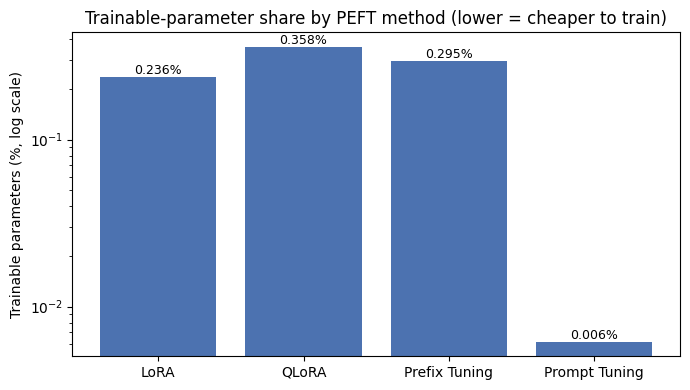

In [59]:
# A simple bar chart comparing trainable-parameter PERCENTAGE across methods (log scale, since the
# differences span more than one order of magnitude).

fig, ax = plt.subplots(figsize=(7, 4))                         # one chart, a readable default size
methods = list(comparison_df.index)                                # method names become the x-axis categories
trainable_pcts = comparison_df["Trainable %"].values                  # the values we're plotting

bars = ax.bar(methods, trainable_pcts, color="#4C72B0")                  # a single, calm, colorblind-friendly blue
ax.set_yscale("log")                                                        # log scale: values differ by orders of magnitude
ax.set_ylabel("Trainable parameters (%, log scale)")
ax.set_title("Trainable-parameter share by PEFT method (lower = cheaper to train)")

# Label each bar with its exact percentage, so the chart is readable without a separate legend/table.
for bar, pct in zip(bars, trainable_pcts):
    # zip(bars, trainable_pcts) pairs up each bar-chart rectangle (from ax.bar() above) with its
    # corresponding percentage value, position-for-position: bars[0] with trainable_pcts[0], and so
    # on - so this loop visits one (bar, pct) pair per method, in the same left-to-right order as
    # the bars themselves, letting the label placed inside the loop attach to the correct bar.
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{pct:.3f}%",
            ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


**Output Explanation**

This is Module 5's bar chart comparing trainable-parameter percentage across all four methods, on a log scale (needed because Prompt Tuning's ~0.006% is roughly 40x smaller than the others, which a linear scale would flatten into invisibility).

**Ranking (lowest to highest):** Prompt Tuning « LoRA < Prefix Tuning < QLoRA — consistent with Module 4's theory that Prompt Tuning (input-only soft prompt) is the cheapest, while Prefix Tuning (per-layer prefixes) trains noticeably more parameters than input-only methods.

**One nuance worth flagging:** QLoRA's own `print_trainable_parameters()` earlier reported the *same* 0.236% as plain LoRA (identical `LoraConfig`, same target module) — the chart's slightly higher 0.358% comes from our own `count_parameters()` helper recomputing `total_params` by summing raw tensor `.numel()`, which counts a 4-bit-packed weight tensor differently than peft's quantization-aware internal count. The trainable parameter *count* (294,912) is genuinely identical to LoRA either way; only this chart's denominator differs slightly for the quantized model.

### Discussion — when should you reach for which method?

- **LoRA** is the strongest general-purpose default today: strong quality-per-trainable-parameter, simple to
  merge for deployment, wide library/tooling support. Start here unless you have a specific reason not to.
- **QLoRA** is LoRA's answer to "the base model doesn't fit in my GPU at all." Reach for it when the *frozen*
  model's memory footprint — not just the trainable adapter — is your bottleneck (e.g. fine-tuning a 13B–70B
  model on a single consumer or single data-center GPU).
- **Prompt Tuning** is the cheapest option in trainable parameters and adapter size, and is attractive when you
  need to store/serve **many** task-specific adapters cheaply, or when the base model is extremely large (its
  quality gap versus full fine-tuning shrinks as scale grows). It tends to underperform at smaller model scales
  like our 124M-parameter `gpt2` demo today.
- **Prefix Tuning** sits between Prompt Tuning and LoRA in both trainable-parameter count and expressiveness —
  a reasonable choice for encoder-decoder or classification-style tasks where per-layer influence over
  attention matters more than for pure short-form generation.

There is no universally "best" method — the right choice depends on your model size, deployment constraints
(single adapter vs. many), and how much of a quality gap you can tolerate versus full fine-tuning.


## Wrap-Up & Further Exercises  

### Best-practice checklist
- ✅ Always call `report_to="none"` (or configure a tracker deliberately) so `Trainer` never prompts for an
  experiment-tracking API key in a shared/workshop environment.
- ✅ Start LoRA with `r=8, lora_alpha=16` and only increase `r` if you have evidence the task needs more capacity.
- ✅ For GPT-2-family architectures target `c_attn`; for Llama-family architectures target
  `["q_proj", "k_proj", "v_proj", "o_proj"]`; always check `model.named_modules()` for your specific architecture.
- ✅ Reach for QLoRA the moment the **frozen base model alone** doesn't comfortably fit your GPU — not before,
  since 4-bit quantization does add a small amount of compute overhead and a small accuracy cost.
- ✅ Prefer `bias="none"` and modest `lora_dropout` (0.0–0.1) as safe LoRA defaults.
- ✅ Save adapters (`save_pretrained`), not merged full models, when you expect to swap between many tasks.
- ✅ Merge (`merge_and_unload`) only for a *single* final deployment target, and only from a non-quantized base
  model.

### Exercises to try after this workshop
1. Increase `r` in Module 2 from 8 → 32 and re-run. How do trainable-parameter count and generation quality change?
2. Change `target_modules` to also include the feed-forward layer (`"c_fc"` in GPT-2) and compare.
3. Swap `BASE_MODEL_NAME` to `"distilgpt2"` (smaller) or `"gpt2-medium"` (larger, needs more memory) and re-run
   the whole notebook — how do the four methods' relative rankings change with model size?
4. Try `prompt_tuning_init=PromptTuningInit.RANDOM` in Module 4 instead of `TEXT` initialization — does training
   converge slower?
5. Load a saved adapter back onto a fresh base model with `PeftModel.from_pretrained(base_model, "./lora_adapter")`
   and confirm it reproduces the same generations as the in-memory model above.

### Further reading (primary sources)
- Hu et al., 2021 — *LoRA: Low-Rank Adaptation of Large Language Models* — [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Dettmers et al., 2023 — *QLoRA: Efficient Finetuning of Quantized LLMs* — [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)
- Li & Liang, 2021 — *Prefix-Tuning: Optimizing Continuous Prompts for Generation* — [arXiv:2101.00190](https://arxiv.org/abs/2101.00190)
- Lester et al., 2021 — *The Power of Scale for Parameter-Efficient Prompt Tuning* — [arXiv:2104.08691](https://arxiv.org/abs/2104.08691)
- Liu et al., 2021 — *P-Tuning v2: Prompt Tuning Can Be Comparable to Fine-tuning Universally Across Scales and Tasks* — [arXiv:2110.07602](https://arxiv.org/abs/2110.07602)
- Hugging Face `peft` documentation — <https://huggingface.co/docs/peft>

**Thank you for attending — happy fine-tuning!**
